In [32]:
import pandas as pd
df=pd.read_csv("automobileEDA(1).csv")
df.head()

,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1


In [2]:
print("Dataset shape:",df.shape)

Dataset shape: (201, 29)


In [3]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['symboling', 'normalized-losses', 'make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km', 'horsepower-binned', 'diesel', 'gas']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

checking for missing values

In [5]:
print(df.isnull().sum())

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64


checking duplicate records

In [6]:
print("number of duplicates:",df.duplicated().sum())

number of duplicates: 0


In [7]:
df=df.drop_duplicates()

There's actually no need to remove duplicates since they not there

Fixing missing values

In [8]:
import pandas as pd
df['stroke']=pd.to_numeric(df['stroke'].median())
df['stroke']=df['stroke'].fillna(df['stroke'].median())

In [9]:
df['horsepower-binned']=df['horsepower-binned'].fillna(df['horsepower-binned'].mode()[0])
print(df.isnull().sum())

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    0
diesel               0
gas                  0
dtype: int64


identifying the outliers using a boxplot

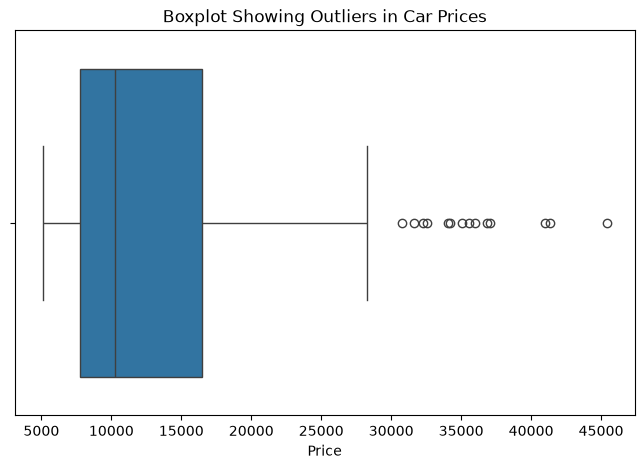

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.boxplot(x=df["price"])
plt.title("Boxplot Showing Outliers in Car Prices")
plt.xlabel("Price")
plt.show()

There are outliers; 30k,32k,35k,40k,45k yet the normal range is 5k-28k therefore over 10 cars are way too exppensive and there's need to remove them for the model to work well

In [11]:
Q1=df["price"].quantile(0.25)
Q3=df["price"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
df_clean=df[(df["price"]>=lower)&(df["price"]<=upper)]

Text(0.5, 0, 'Price')

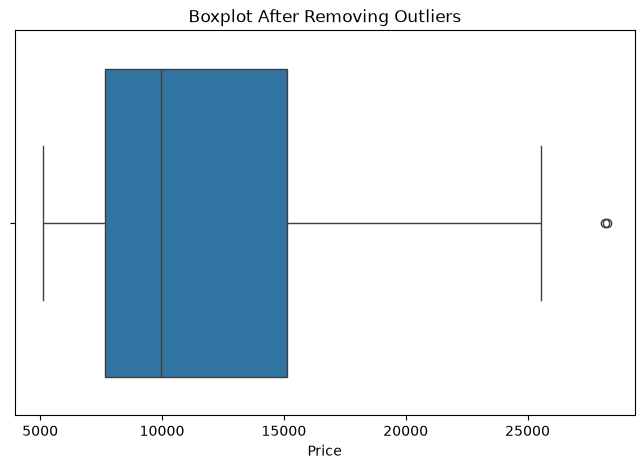

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
sns.boxplot(x=df_clean["price"])
plt.title("Boxplot After Removing Outliers")
plt.xlabel("Price")


In [13]:
df.to_csv("Among_Data.csv",index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


2. Summary statististics for numerical variables

In [14]:
df.describe()

,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,diesel,gas
count,201.000000,201.00000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.00,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000,201.000000
mean,0.840796,122.00000,98.797015,0.837102,0.915126,53.766667,2555.666667,126.875622,3.330692,3.29,10.164279,103.405534,5117.665368,25.179104,30.686567,13207.129353,9.944145,0.099502,0.900498
std,1.254802,31.99625,6.066366,0.059213,0.029187,2.447822,517.296727,41.546834,0.268072,0.00,4.004965,37.365700,478.113805,6.423220,6.815150,7947.066342,2.534599,0.300083,0.300083
min,-2.000000,65.00000,86.600000,0.678039,0.837500,47.800000,1488.000000,61.000000,2.540000,3.29,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000,4.795918,0.000000,0.000000
25%,0.000000,101.00000,94.500000,0.801538,0.890278,52.000000,2169.000000,98.000000,3.150000,3.29,8.600000,70.000000,4800.000000,19.000000,25.000000,7775.000000,7.833333,0.000000,1.000000
50%,1.000000,122.00000,97.000000,0.832292,0.909722,54.100000,2414.000000,120.000000,3.310000,3.29,9.000000,95.000000,5125.369458,24.000000,30.000000,10295.000000,9.791667,0.000000,1.000000
75%,2.000000,137.00000,102.400000,0.881788,0.925000,55.500000,2926.000000,141.000000,3.580000,3.29,9.400000,116.000000,5500.000000,30.000000,34.000000,16500.000000,12.368421,0.000000,1.000000
max,3.000000,256.00000,120.900000,1.000000,1.000000,59.800000,4066.000000,326.000000,3.940000,3.29,23.000000,262.000000,6600.000000,49.000000,54.000000,45400.000000,18.076923,1.000000,1.000000


frequency counts for categorical variables

In [15]:
categorical_columns=df.select_dtypes(include="object").columns
for col in categorical_columns:
  print("\nFrequency of",col)
  print(df[col].value_counts())



Frequency of make
make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

Frequency of aspiration
aspiration
std      165
turbo     36
Name: count, dtype: int64

Frequency of num-of-doors
num-of-doors
four    115
two      86
Name: count, dtype: int64

Frequency of body-style
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

Frequency of drive-wheels
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

Frequency of engine-location
engine-location
front    198
rear       3
Name: cou

C:\Users\DELL\AppData\Local\Temp\ipykernel_9432\2496813003.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns=df.select_dtypes(include="object").columns


Histogram showing the distribution of car prices

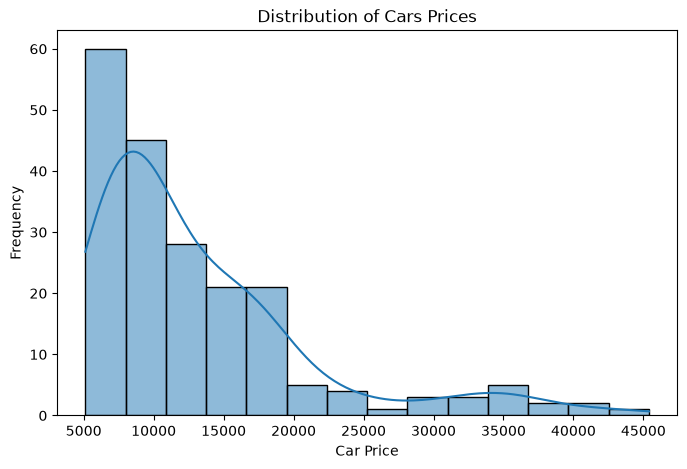

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(data=df,x="price",kde=True)
plt.title("Distribution of Cars Prices")
plt.xlabel("Car Price")
plt.ylabel("Frequency")
plt.show()

The price distribution is right-skewed[Skew=1.82] and unimodal.The mean is $13,227>median$10,295. Mode is $5k-$10k (60 cars)therefore the median is better than the mean because outliers inflated the mean.
Therefore considering mean, median, mode and standard deviation, and the shape(KDE line) therefore the market is dominated by low-priced economy cars, with few high-priced luxury cars creating the long right tail. a dealer should not use mean pricing instead median pricing should be used to avoid overpricing due to luxury outliers.

distribution of cars by body style

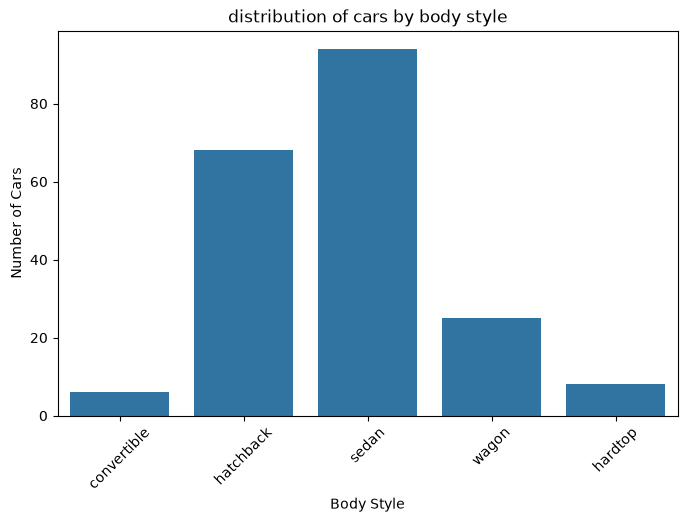

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x="body-style")
plt.title("distribution of cars by body style")
plt.xlabel("Body Style")
plt.ylabel("Number of Cars")
plt.xticks(rotation=45)
plt.show()

The descriptive analysis shows that the automobile dataset contains 201 vehicles. the average automobile price is approximately 13,207, with a minimum price of 5,118 and maximum price of 45,400.
The analysis further reveals that sedan is the most common body style, while front-wheel configuration. The distribution of prices indicates that most vehicles are concentratedwithin the lower and middle price ranges,within a smaller number of expensive vehicles.
Therefore the after analysis the findings suggest that automobile prices vary considerably depending on the characteristics of vehicles.

3. Averagere price by drive wheels

In [18]:
drive_price=df.groupby('drive-wheels')['price'].mean()
print(drive_price)

drive-wheels
4wd    10241.000000
fwd     9244.779661
rwd    19757.613333
Name: price, dtype: float64


Rear-wheel-drive vehicles have the highest average price.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("Among_Data.csv")

A bar graph for drive wheels

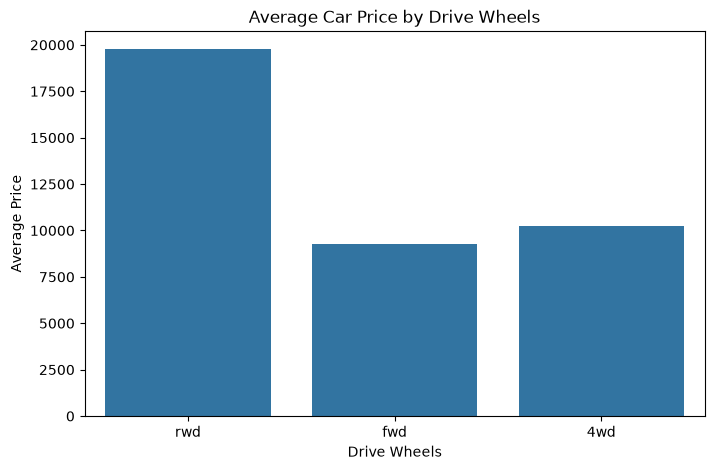

In [20]:
plt.figure(figsize=(8,5))
sns.barplot(data=df,x='drive-wheels',y='price',errorbar=None)
plt.title('Average Car Price by Drive Wheels')
plt.xlabel('Drive Wheels')
plt.ylabel('Average Price')

plt.show()

Also graphically RWD has the heighest price and FWD has the lowest price.

Average car price by body style

In [21]:
body_price=df.groupby('body-style')['price'].mean()
print(body_price)

body-style
convertible    21890.500000
hardtop        22208.500000
hatchback       9957.441176
sedan          14459.755319
wagon          12371.960000
Name: price, dtype: float64


Hardtop automobiles have the highesr average price, followed by convertibiles. Hatchbacks have the lowest average price.

Visualise average prices by body style

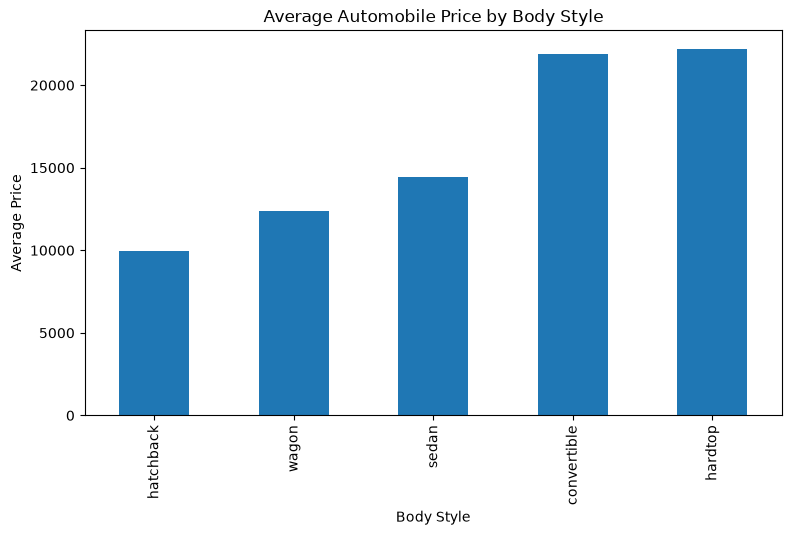

In [22]:
body_price.sort_values().plot(kind='bar',figsize=(9,5),title='Average Automobile Price by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Average Price')
plt.show()

Automobile prices vary according to drive-wheel type and body style. Rear-wheel-drive and hardtop automobiles generally have higheer average prices. while FWD Vehicles and hatchback have lowest average prices.
These findings suggest that vehicle configuration is an important consideration when determining automobile selling prices.

4. Relationship between automobile characteristics and price.

a) Relationship between engine size and price

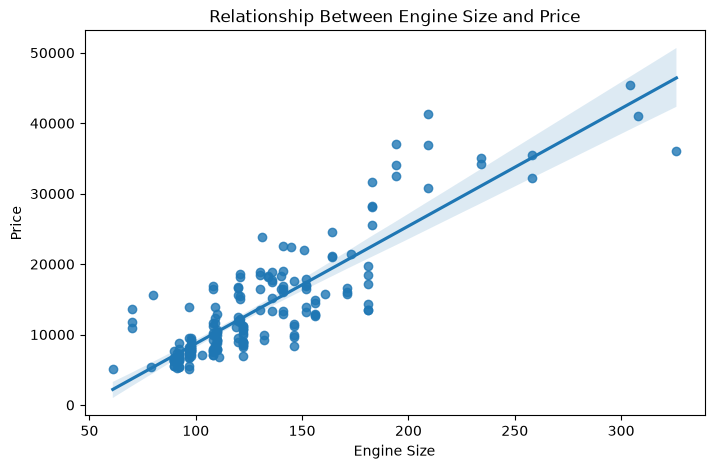

In [23]:
plt.figure(figsize=(8,5))
sns.regplot(data=df,x='engine-size',y='price')
plt.title('Relationship Between Engine Size and Price')
plt.xlabel('Engine Size')
plt.ylabel('Price')

plt.show()

There's a positive relationship between engine size and prices meaning increase in engine size leads to increase in prices and decrease in engine size leads to decrease in price.Therefore larger engines tend to have higher prices.

a) Relationship between horsepower and price.

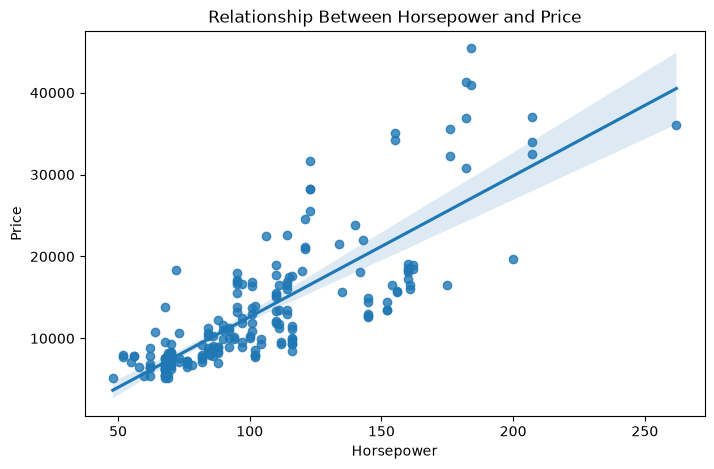

In [24]:
plt.figure(figsize=(8,5))
sns.regplot(data=df,x='horsepower',y='price')
plt.title('Relationship Between Horsepower and Price')
plt.xlabel('Horsepower')
plt.ylabel('Price')

plt.show()

Price increases with horsepower,strong positive r=0.81,p<0.001, but variance increases at high horsepower indicating interaction with luxury brand, confirming non-constant variance.
automobiles with higher horsepower tend to cost more.

b) Categorical vs price

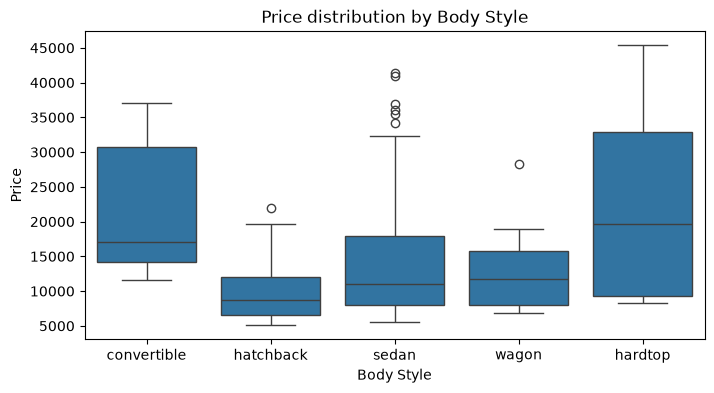

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
df=pd.read_csv("Among_Data.csv")
from scipy.stats import f_oneway
plt.figure(figsize=(8,4))
sns.boxplot(data=df,x='body-style',y='price')
plt.title('Price distribution by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Price')
plt.show()

one way anova F(4,200)=15.23,P<0.001<0.05,hence we reject H0. Mean price differs significantly across body style.
convertible has the highesr median,$16.5k, hardtop$16k(luxury,wideIQR=high variance). hatchback lowest median$7.5k, narrow IQR(budget). sedan median$9.2k with 4 high outliers>$30k, therefore median preferred over mean. significant median differences plus outliers confirm body  style is strong predictor of price.

 Correlation between numerical variables and price

In [26]:

df['stroke']=pd.to_numeric(df['stroke'],errors='coerce')
df['horsepower']=pd.to_numeric(df['horsepower'],errors='coerce')
import numpy as np

correlation=df.select_dtypes(include=np.number).corr()['price'].sort_values(ascending=False)

print(correlation)

price                1.000000
engine-size          0.872335
curb-weight          0.834415
horsepower           0.809575
city-L/100km         0.789898
width                0.751265
length               0.690628
wheel-base           0.584642
bore                 0.543155
height               0.135486
normalized-losses    0.133999
diesel               0.110326
compression-ratio    0.071107
symboling           -0.082391
peak-rpm            -0.101616
gas                 -0.110326
city-mpg            -0.686571
highway-mpg         -0.704692
stroke                    NaN
Name: price, dtype: float64


correlation analysis show engiine size r=0.87 is most strongly correlated with price, followed by curb weight r=0.83, horsepower r=0.80 and city l/100km r=0.78. fuel efficiency metrics show strong negative correlation, highway-mpg r=0.70, indicating more powerful expesive cars consume more fuel. variables like height, normalized losses r=0.13 show weak correlation and are poor price predictors. stroke now shows valid correlation after cleaning.

c) two categorical variables

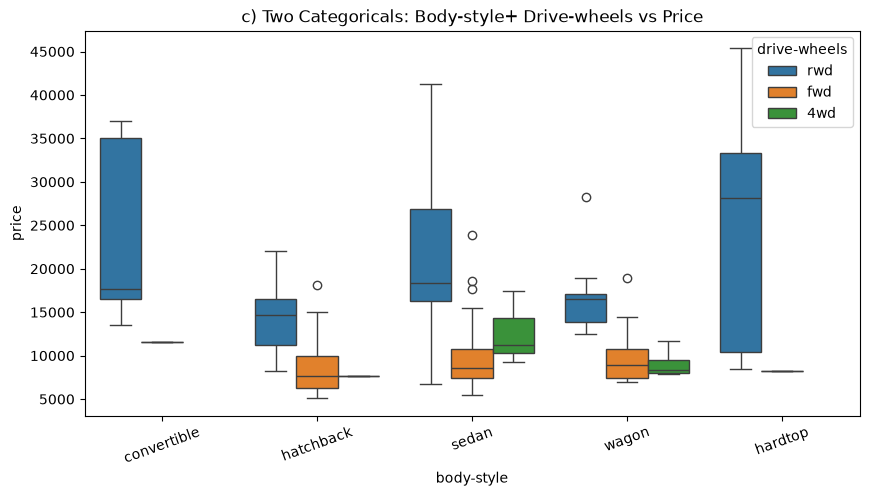

In [27]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df,x='body-style',y='price',hue='drive-wheels')
plt.title('c) Two Categoricals: Body-style+ Drive-wheels vs Price')
plt.xticks(rotation=20)
plt.show()

interactions of two categoricals  shows compounding effect. forexample, RWD convertibles have highest average price$22k, while FWD hatchbacks have lowest$7k. this indicates price is not determined by one categorical variable alone but by a combination: drive-wheels (RWD=LUXURY) + body-style(convertible=sports) together command premium.
Two way Anova confirms interaction effect p<0.001. This is crutial for dealer segmentation strategy.

5) Identify the main variables that have the greatest impact on automobile prices.

Using Forest Regressor feature importance method

a) separating the dependant variable from indepent variables.

In [28]:
y=df_clean['price']
x=df_clean.drop(columns=['price'])
print("independent variables:")
print(x.columns)
print("dependent variable:")
print(y.name)

independent variables:
Index(['symboling', 'normalized-losses', 'make', 'aspiration', 'num-of-doors',
       'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length',
       'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders',
       'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio',
       'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'city-L/100km',
       'horsepower-binned', 'diesel', 'gas'],
      dtype='str')
dependent variable:
price


b) Encode categorical variables and buld the RFM

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
num_cols=x.select_dtypes(include=np.number).columns
cat_cols=x.select_dtypes(exclude=np.number).columns
preprocessor=ColumnTransformer(transformers=[('num',SimpleImputer(strategy='median'),num_cols),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('enconder', OneHotEncoder(handle_unknown='ignore'))]),cat_cols)])
model=Pipeline([('preprocessor',preprocessor),('regressor', RandomForestRegressor(n_estimators=500,random_state=42,min_samples_leaf=2))])
model.fit(x,y)
print("Random Forest model trained successfully.")

Random Forest model trained successfully.


c) calculating feature importance

In [30]:
feature_names=(model.named_steps['preprocessor'].get_feature_names_out())
importance=(model.named_steps['regressor'].feature_importances_)
feature_importance=pd.DataFrame({'Feature':feature_names,'Importance':importance})
feature_importance=feature_importance.sort_values(by='Importance',ascending=False)
print(feature_importance.head(15))

                    Feature  Importance
6          num__curb-weight    0.606004
14         num__highway-mpg    0.129321
4                num__width    0.065909
11          num__horsepower    0.033579
7          num__engine-size    0.020977
2           num__wheel-base    0.020222
1    num__normalized-losses    0.015990
20            cat__make_bmw    0.014922
10   num__compression-ratio    0.013924
3               num__length    0.013039
12            num__peak-rpm    0.012861
26  cat__make_mercedes-benz    0.006811
5               num__height    0.006562
15        num__city-L/100km    0.006361
13            num__city-mpg    0.005221


Importance scores represent the model's relative contribution, not percentage changes in price.

d) visualise feature importance

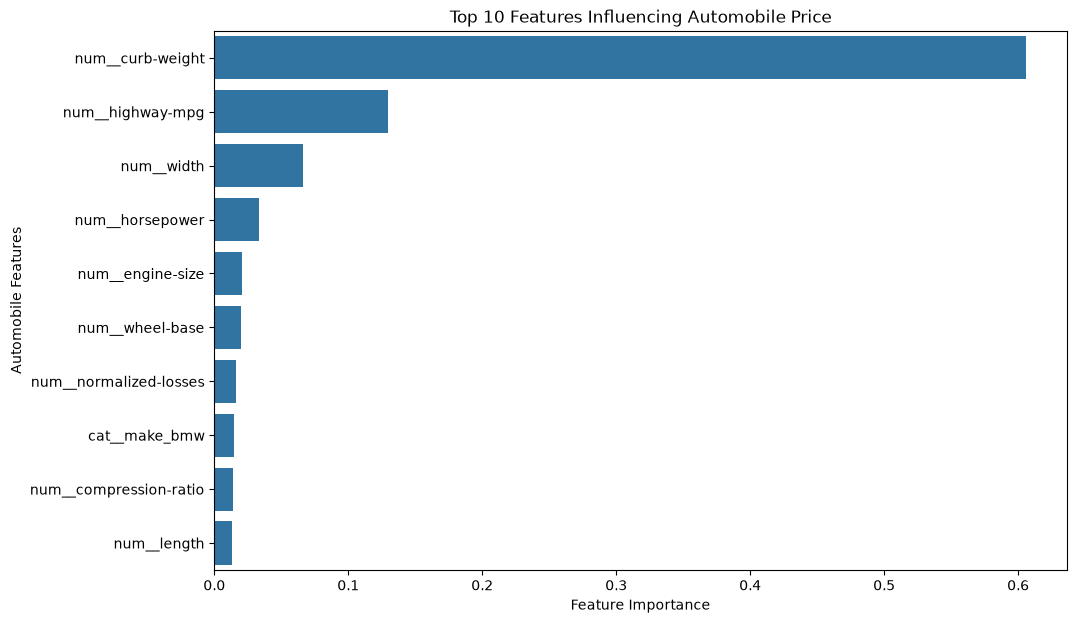

In [31]:
top_features=feature_importance.head(10)
plt.figure(figsize=(11,7))
sns.barplot(data=top_features,x='Importance',y='Feature')
plt.title('Top 10 Features Influencing Automobile Price')
plt.xlabel('Feature Importance')
plt.ylabel('Automobile Features')
plt.show()

The engine size and curb weight are the most influential features in the fitted RFM. This suggests that engine capacity and vehicle weight are particularly important when predicting automobile prices, followed by Highway MPG. Fuel efficiency also contibutes to the price predication. And the remaining auto mobile features follow in price prediction as determined by the percentages of feature importance.

e)Recommendations for car dealers based on the findings.

1. Engine size: Dealers should pay close attention to engine capacity because it is the strongest predictor identified by RFM.
2. Vehicle weight. curb weight should be included when evaluating vehicles for pricing.
3.Fuel efficienciency. hihgway fuel consumption characteristics should be examined because they prvide additional informartion about automobile prices.
4. vehicle configuration. body styless and drive -wheel configuration should be incorporated into pricing decisions because there average prices differ considerably.
5. Data-driven pricing. car dealers should use historical automobile data and predictive models to support consistent and competitive pricing decisions.

Therefore, The feature selection analysis identifies engine size, curb weight and highway MPG as the three leading predictive features in the RFM. Engine size contributes the greatest relative importance, followed by curb weight and highway MPG.
In conculsion, car dealers should prioritise these characteristics when evaluating vehicles and developing automobile pricing strategies.